# Đồ án Phân tích Dữ liệu (SGU — CBGD: Phan Thành Huấn)
## Phân tích mối liên hệ giữa khí tượng và năng suất lúa ở Đồng bằng sông Cửu Long theo ba mùa vụ (2015–2024)

**Sinh viên thực hiện:** Lê Thị Ngọc Giàu (`3123410088`) · Trần Ngọc An (`3123410004`)

**Phạm vi chính thức (`DeTaiPTDL.pdf`):** Toàn vùng 13/13 tỉnh ĐBSCL (2015–2024) qua 2 tuyến song hành:
- **Tuyến A (Toàn vùng 13 tỉnh):** Đông Xuân (`n = 127`) và cụm Hè Thu–Thu Đông (`n = 130`), tổng `257` quan sát.
- **Tuyến B (Tách riêng 3 mùa vụ):** An Giang, Kiên Giang, Cần Thơ (`n = 90`, 40,5% sản lượng toàn ĐBSCL) + `7` bản ghi ngoại kiểm địa lý OOD (`Tiền Giang`, `Vĩnh Long`, `Cà Mau`).

Notebook này lưu sẵn toàn bộ kết quả thực thi thực tế theo quy trình **KDD (Buổi 01 → Buổi 12)**: Ngoại lệ $3\sigma$ (Buổi 02) → Nghịch lý Simpson & VIF (Buổi 03–04) → Kiểm định 4 giả định OLS GĐ1–GĐ4, Chọn biến & Ridge/Lasso (Buổi 04) → 20 mô hình Hồi quy (Buổi 04 + 08–10) → 10 mô hình Phân lớp (Buổi 08–10) → 9 thuật toán Gom cụm 13 tỉnh & Dendrogram (Buổi 11–12) → Luật kết hợp Apriori (Buổi 06–07).

In [1]:
import os, json, subprocess
import pandas as pd
from IPython.display import Image, display

if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
print('Working directory:', os.getcwd())
ver = json.load(open('docs/cleaning_verification_report.json', encoding='utf-8'))
print('Cleaning Verification Gate PASS:', ver['cleaning_verification_passed'], '| Ready:', ver['ready_for_eda_and_modeling'])

Working directory: d:\mekong-rice-yield-analysis
Cleaning Verification Gate PASS: True | Ready: True


## Bước 1. Kiểm chứng thực thi toàn bộ Pipeline Phân tích, Khai phá & Dashboard
Tái lập 100% offline từ `data/processed/` đã qua kiểm định tự động.

In [2]:
for script in ['scripts/run_eda_and_modeling.py', 'scripts/run_statistical_and_datamining_suite.py', 'scripts/build_dashboard.py']:
    res = subprocess.run(['python', script], capture_output=True, text=True, encoding='utf-8')
    assert res.returncode == 0, res.stderr
    print(f'[OK] {script} -> exit_code={res.returncode} ({len(res.stdout.splitlines())} lines output)')

[OK] scripts/run_eda_and_modeling.py -> exit_code=0 (101 lines output)
[OK] scripts/run_statistical_and_datamining_suite.py -> exit_code=0 (113 lines output)
[OK] scripts/build_dashboard.py -> exit_code=0 (4 lines output)


## Bước 2. Tóm tắt Mô tả & Kiểm định Ngoại lệ Quy tắc $3\sigma$ (Buổi 02)

Các điểm ngoại lệ năng suất vượt ngưỡng 3-sigma (|z| > 3):


dataset,count,mean,std,min,median,max,outliers_3sigma_count
track_b_3seasons_90,90,6.1275,0.8611,4.65,5.8565,7.75,0
track_a_dx_13prov_127,127,6.6375,1.1990,0.04,6.9600,7.82,3
track_a_ht_td_13prov_130,130,5.3911,0.5612,3.47,5.5550,6.42,1


dataset,province,harvest_year,season,yield_t_ha,z_score,domain_outlier_flag
track_a_dx_13prov_127,Bến Tre,2016,dong_xuan,0.05,-5.494,extreme_salinity_crop_failure
track_a_dx_13prov_127,Cà Mau,2017,dong_xuan,3.00,-3.034,none
track_a_dx_13prov_127,Bến Tre,2020,dong_xuan,0.04,-5.502,extreme_salinity_crop_failure
track_a_ht_td_13prov_130,Bến Tre,2020,he_thu_thu_dong_combined,3.47,-3.423,none


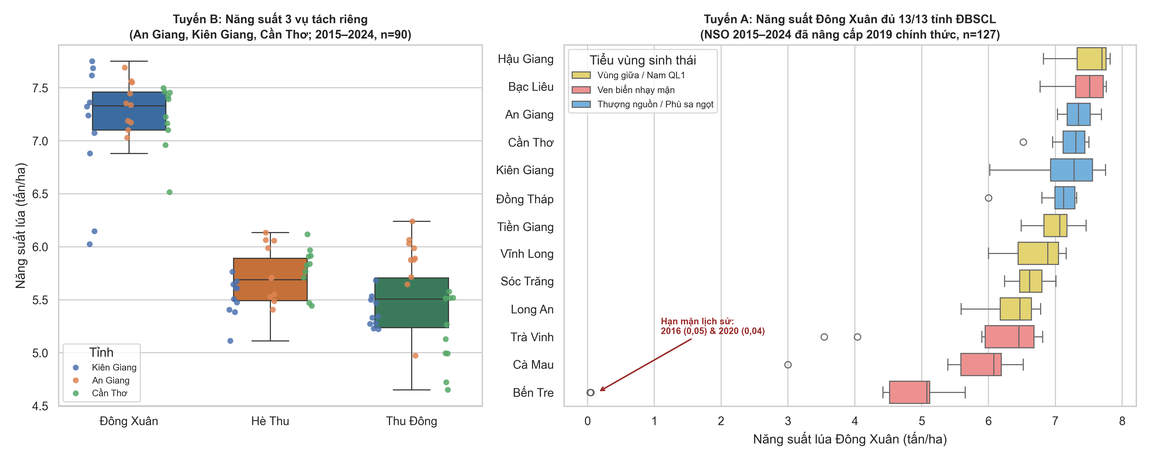

In [3]:
desc = pd.read_csv('results/metrics/eda_descriptive_summary.csv')
outliers = pd.read_csv('results/metrics/eda_3sigma_outliers_audit.csv')
display(desc[desc['feature'] == 'yield_t_ha'][['dataset','count','mean','std','min','median','max','outliers_3sigma_count']])
print('Các điểm ngoại lệ năng suất vượt ngưỡng 3-sigma (|z| > 3):')
display(outliers[outliers['flag_3sigma']][['dataset','province','harvest_year','season','yield_t_ha','z_score','domain_outlier_flag']])
display(Image('results/figures/01_eda_yield_by_season_and_province.png', width=950))

## Bước 3. Phát hiện KDD: Nghịch lý Simpson (Đảo dấu 8/8 biến), VIF & Kiểm định 4 Giả định OLS GĐ1–GĐ4 (Buổi 03–04)

Nghịch lý Simpson — 8 biến đảo ngược dấu sau khi khử cố định Tỉnh x Vụ:


feature,raw_pearson_r,within_pearson_r,within_p_value
t2m_max_mean_c,0.4263,-0.1478,0.1645
t2m_max_peak_c,0.4098,-0.1096,0.3037
precip_total_mm,-0.7378,0.3691,0.0003
rh2m_mean_pct,-0.6264,0.1586,0.1355
vpd_mean_kpa,0.4900,-0.1598,0.1325
hot_days_gt35c,0.4750,-0.0831,0.4363
dry_days_lt1mm,0.8810,-0.0926,0.3852
heavy_rain_days_gt20mm,-0.5802,0.3809,0.0002


feature,r2_on_others,vif,feature_set
t2m_mean_c,0.9511,20.47,raw_7_collinear
t2m_max_mean_c,0.9813,53.47,raw_7_collinear
t2m_max_peak_c,0.8612,7.20,raw_7_collinear
precip_total_mm,0.8343,6.04,raw_7_collinear
rh2m_mean_pct,0.9734,37.60,raw_7_collinear
hot_days_gt35c,0.9547,22.05,raw_7_collinear
dry_days_lt1mm,0.9772,43.93,raw_7_collinear
vpd_mean_kpa,0.7187,3.55,orthogonal_5_physical
precip_total_mm,0.5912,2.45,orthogonal_5_physical
ws2m_mean_ms,0.0859,1.09,orthogonal_5_physical


model,n,r2,adj_r2,f_pvalue_gd1,shapiro_p_gd2,max_vif_gd3,bp_p_gd4,white_p_gd4,aic,bic
TrackB_Direct_OneHot_Ortho5_Year_n90,90,0.9137,0.9027,0.000000,0.141193,11.28,0.080626,0.128084,29.035,56.533
TrackB_FE_Demeaned_Ortho5_Year_n90,90,0.4920,0.4553,0.000000,0.000122,2.90,0.369547,0.191532,-6.083,11.416
TrackA_DX_Full_13Prov_n127,127,0.2280,0.1894,0.000020,0.000000,6.35,0.227595,0.462820,273.281,293.190
TrackA_DX_ExSalinity_13Prov_n125,125,0.2724,0.2354,0.000001,0.000000,6.29,0.862605,0.928102,165.460,185.258
TrackA_HTTD_13Prov_n130,130,0.4762,0.4507,0.000000,0.000355,3.59,0.140726,0.033386,-54.809,-34.736


selection_method,n_features,adj_r2,aic,bic,max_vif,ols_cv_mae,ridge_test_mae
Full_Candidate_10Weather_Plus_Year,11,0.4995,-10.125,17.195,353.84,0.2520,0.1880
Forward_Selection_AIC,6,0.5177,-17.019,-1.082,13.61,0.2347,0.1612
Backward_Elimination_p005,3,0.4869,-15.326,-6.220,18.34,0.1623,0.1320
Stepwise_Bidirectional_AIC,4,0.5088,-17.525,-6.142,6.52,0.1692,0.1460
Domain_Orthogonal_5_Plus_Year,6,0.3744,1.707,17.644,3.43,0.1993,0.1613


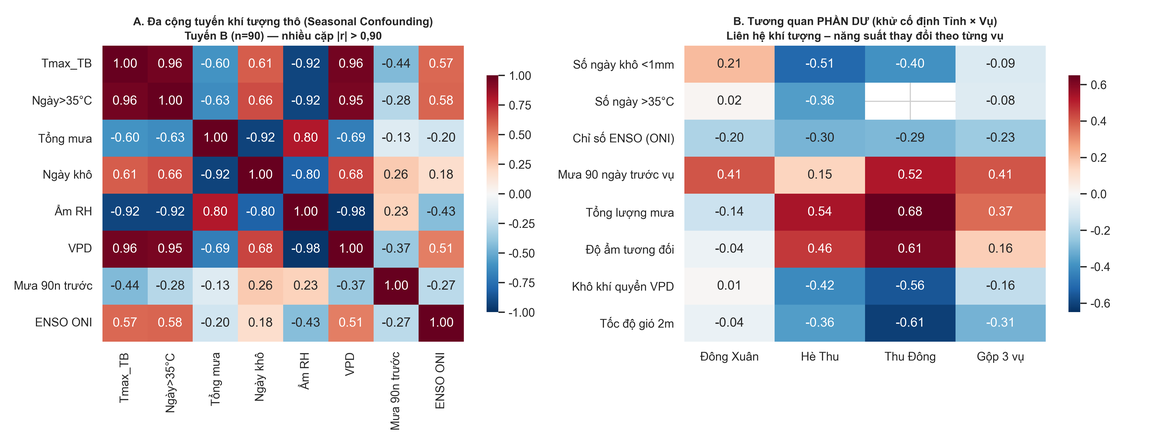

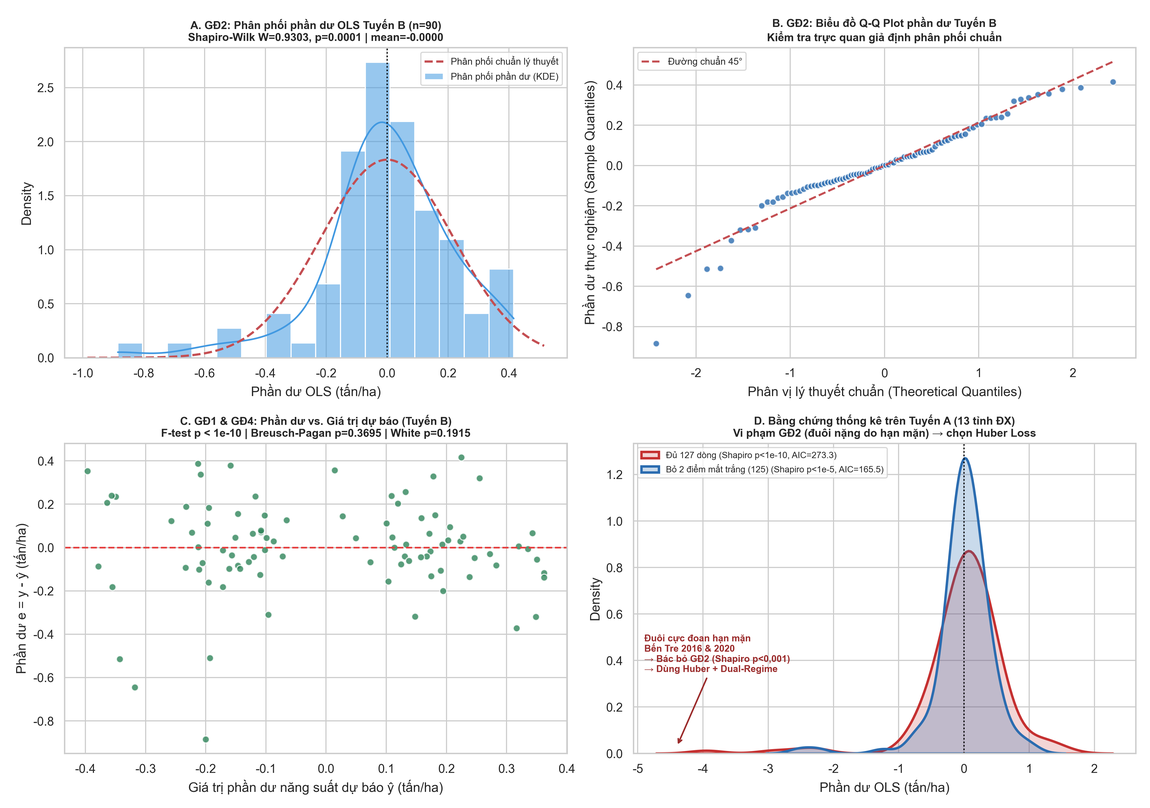

In [4]:
wcorr = pd.read_csv('results/metrics/eda_within_correlations.csv')
simp = wcorr[(wcorr['track']=='track_b_3seasons') & (wcorr['scope']=='all_3_seasons_pooled') & (wcorr['raw_pearson_r']*wcorr['within_pearson_r'] < 0)]
print('Nghịch lý Simpson — 8 biến đảo ngược dấu sau khi khử cố định Tỉnh x Vụ:')
display(simp[['feature','raw_pearson_r','within_pearson_r','within_p_value']])
display(pd.read_csv('results/metrics/eda_vif_comparison.csv'))
display(pd.read_csv('results/metrics/ols_assumptions_diagnostics_gd1_to_gd4.csv')[['model','n','r2','adj_r2','f_pvalue_gd1','shapiro_p_gd2','max_vif_gd3','bp_p_gd4','white_p_gd4','aic','bic']])
display(pd.read_csv('results/metrics/feature_selection_stepwise_comparison.csv')[['selection_method','n_features','adj_r2','aic','bic','max_vif','ols_cv_mae','ridge_test_mae']])
display(Image('results/figures/02_eda_collinearity_and_within_corr.png', width=950))
display(Image('results/figures/07_ols_assumptions_diagnostics_gd1_gd4.png', width=950))

## Bước 4. So sánh Đa hình thái Mô hình Hồi quy (20 mô hình Tuyến B & 14 mô hình Tuyến A), Độ nhạy & OOD

model,train_2015_2022_mae,expanding_cv_mae,test_2023_2024_mae,test_2023_2024_rmse,test_2023_2024_r2
Baseline_Median,0.2109,0.2624,0.3002,0.3400,0.8424
Structural_FE_Mean,0.2182,0.2936,0.3263,0.3802,0.8029
Structural_FE_Plus_Trend,0.1718,0.1988,0.1335,0.1681,0.9615
OLS_Anomaly_Core4,0.1734,0.2303,0.4220,0.4678,0.7016
OLS_Anomaly_Ortho5_Trend,0.1682,0.1993,0.1565,0.2089,0.9405
Ridge_Anomaly_Ortho5,0.1725,0.2104,0.3278,0.3686,0.8147
Ridge_Anomaly_Ortho5_Trend,0.1654,0.1881,0.1369,0.1842,0.9538
Lasso_Anomaly_Ortho5,0.1723,0.2170,0.3303,0.3722,0.8111
Lasso_Anomaly_Ortho5_Trend,0.1662,0.1867,0.1374,0.1841,0.9538
Huber_Anomaly_Ortho5,0.1677,0.1844,0.2940,0.3339,0.8480


model,expanding_cv_mae,test_2023_2024_mae,test_2023_2024_rmse
Baseline_Median_Prov,0.5070,0.3019,0.3257
Structural_Prov_Mean,0.6242,0.4746,0.5933
Structural_Prov_Plus_Trend,0.5798,0.1754,0.2167
OLS_Anomaly_Weather,0.7180,0.6840,0.8053
Ridge_Anomaly_Weather,0.5856,0.5002,0.5518
Lasso_Anomaly_Weather,0.6239,0.5692,0.6483
Huber_Anomaly_Weather,0.4482,0.4086,0.4575
Huber_Anomaly_Weather_ONI_Coastal,0.4646,0.4198,0.4809
Huber_Anomaly_Weather_Trend,0.4524,0.3268,0.3773
DecisionTree_Anomaly,0.5572,0.4182,0.4906


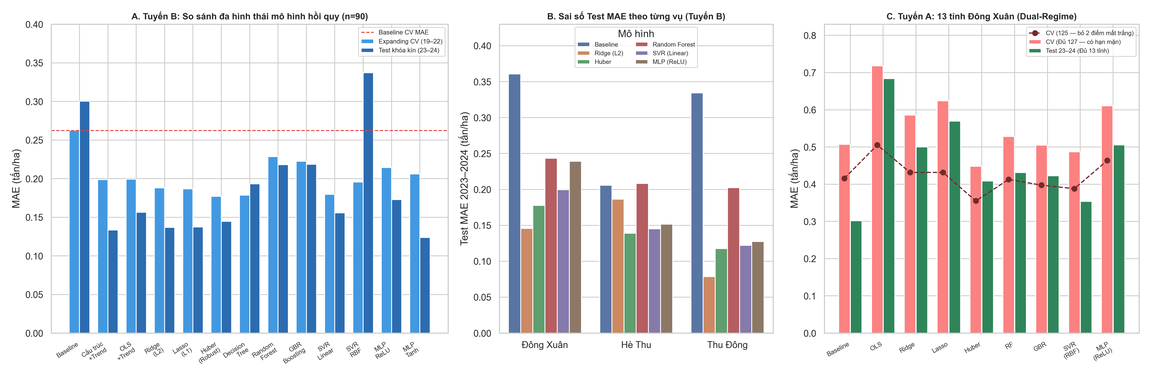

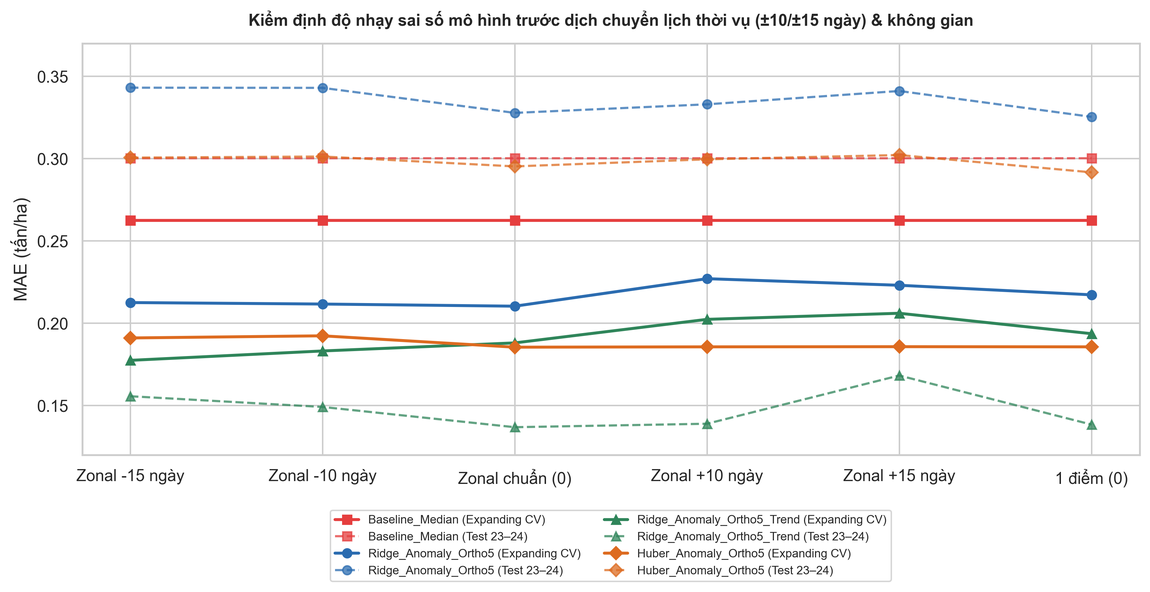

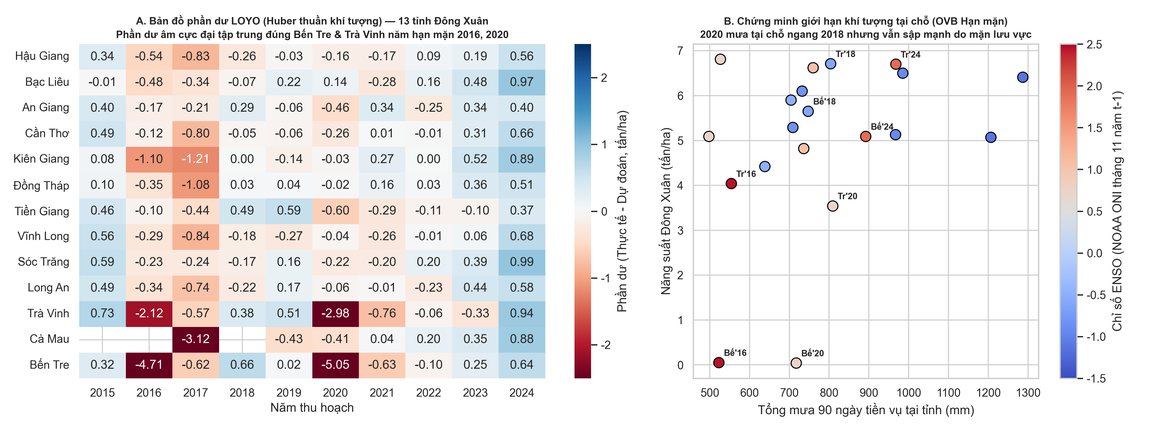

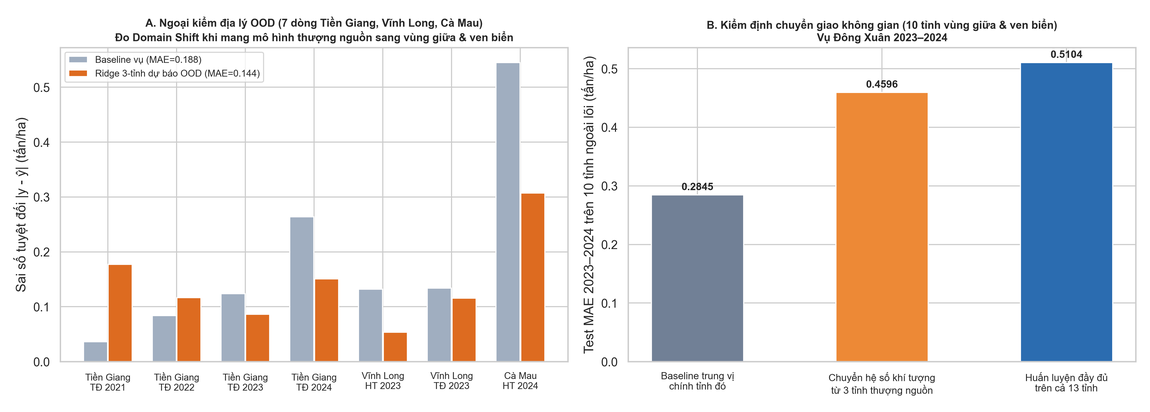

In [5]:
display(pd.read_csv('results/metrics/track_b_3seasons_model_comparison.csv')[['model','train_2015_2022_mae','expanding_cv_mae','test_2023_2024_mae','test_2023_2024_rmse','test_2023_2024_r2']])
ta = pd.read_csv('results/metrics/track_a_delta13_model_comparison.csv')
display(ta[ta['suite']=='delta13_dong_xuan_full_127'][['model','expanding_cv_mae','test_2023_2024_mae','test_2023_2024_rmse']])
display(Image('results/figures/03_model_comparison_tier1_and_tier2.png', width=1020))
display(Image('results/figures/04_sensitivity_calendar_and_spatial.png', width=860))
display(Image('results/figures/05_residual_attribution_salinity_13provinces.png', width=950))
display(Image('results/figures/06_spatial_generalization_ood_check.png', width=950))

## Bước 5. So sánh Đa hình thái Mô hình Phân lớp (10 hình thái — Buổi 08–10) & Luật Cây Quyết định CART

=== DECISION TREE (CART) IF-THEN RULES — TASK C1 (3-Class Yield Tier: Weather + Subregion) ===
Classes: 0 = Thap (< 5.58), 1 = Trung binh (5.58-6.49), 2 = Cao (>= 6.49 t/ha)

|--- precip_total_mm <= -0.64
|   |--- ws2m_mean_ms <= 2.26
|   |   |--- ecological_subregion_upstream_alluvial_3crop <= 0.50
|   |   |   |--- vpd_mean_kpa <= 1.36
|   |   |   |   |--- class: 2
|   |   |   |--- vpd_mean_kpa >  1.36
|   |   |   |   |--- class: 1
|   |   |--- ecological_subregion_upstream_alluvial_3crop >  0.50
|   |   |   |--- ws2m_mean_ms <= -0.23
|   |   |   |   |--- class: 2
|   |   |   |--- ws2m_mean_ms >  -0.23
|   |   |   |   |--- class: 2
|   |--- ws2m_mean_ms >  2.26
|   |   |--- class: 0
|--- precip_total_mm >  -0.64
|   |--- precip_total_mm <= 1.06
|   |   |--- ecological_subregion_coastal_salinity_prone <= 0.50
|   |   |   |--- pre_season_rain_90d_mm <= -1.14
|   |   |   |   |--- class: 0
|   |   |   |--- pre_season_rain_90d_mm >  -1.14
|   |   |   |   |--- class: 1
|   |   |--- ecologic

model,skf5_f1,exp_cv_f1,test_acc,test_f1,test_auc
Dummy_Baseline,0.1679,0.1374,0.2115,0.1164,0.5000
Logistic_Multinomial,0.7553,0.7759,0.7885,0.7831,0.9614
Logistic_OvR,0.7388,0.7561,0.8462,0.8360,0.9577
DecisionTree_CART,0.6068,0.6122,0.6154,0.5987,0.7135
RandomForest,0.6551,0.6863,0.7115,0.6710,0.9326
GradientBoosting,0.7191,0.7623,0.6923,0.6550,0.9330
NaiveBayes_Gaussian,0.7088,0.7186,0.6923,0.6349,0.9644
SVM_Linear,0.7612,0.7874,0.8077,0.7966,0.9669
SVM_RBF,0.7502,0.8012,0.8654,0.8717,0.9487
MLP_ReLU,0.7559,0.7540,0.5769,0.4600,0.9068


model,test_acc,test_precision,test_recall,test_f1,test_auc
Dummy_Baseline,0.6154,0.0000,0.00,0.0000,0.5000
Logistic_Binary,0.5385,0.4167,0.50,0.4545,0.5687
DecisionTree_CART,0.5769,0.4286,0.30,0.3529,0.4742
RandomForest,0.4615,0.2778,0.25,0.2632,0.3891
GradientBoosting,0.5385,0.2500,0.10,0.1429,0.4008
NaiveBayes_Gaussian,0.5192,0.3077,0.20,0.2424,0.5156
SVM_Linear,0.5577,0.4444,0.60,0.5106,0.5875
SVM_RBF,0.5577,0.3636,0.20,0.2581,0.4828
MLP_ReLU,0.6154,0.0000,0.00,0.0000,0.5938
MLP_Tanh,0.6154,0.0000,0.00,0.0000,0.5844


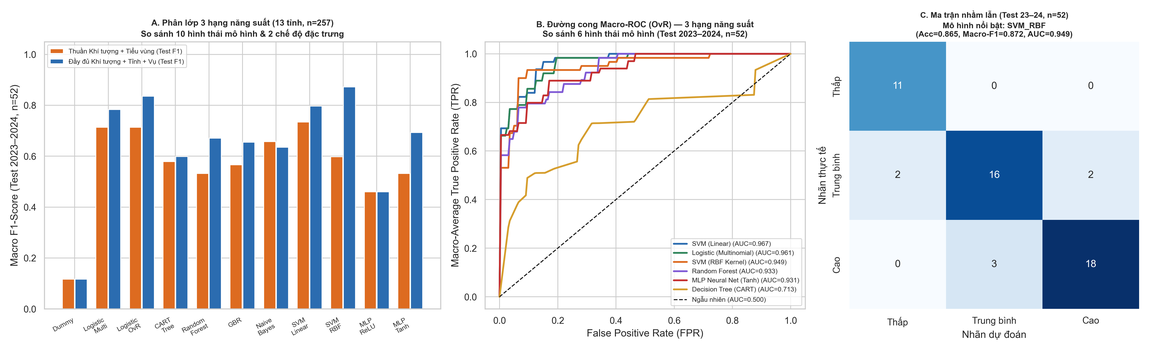

In [6]:
clf_df = pd.read_csv('results/metrics/classification_multimodel_comparison.csv')
display(clf_df[clf_df['feature_regime']=='full_context'][['model','skf5_f1','exp_cv_f1','test_acc','test_f1','test_auc']])
display(clf_df[clf_df['task']=='C2_Binary_UnderperformRisk'][['model','test_acc','test_precision','test_recall','test_f1','test_auc']])
print(open('results/metrics/classification_decision_tree_rules.txt', encoding='utf-8').read())
display(Image('results/figures/08_classification_multimodel_roc_and_cm.png', width=1020))

## Bước 6. Gom cụm 13 Tỉnh ĐBSCL (9 Thuật toán + Dendrogram — Buổi 11–12)

algorithm,n_clusters_found,n_noise_points,internal_sse,internal_silhouette,internal_calinski_harabasz,external_ari_vs_subregion,external_nmi_vs_subregion
KMeans_K3,3,0,30.3217,0.3898,14.2931,0.1374,0.3838
KMedoids_PAM_K3,3,0,30.3217,0.3898,14.2931,0.1374,0.3838
Agglomerative_Ward_K3,3,0,30.3217,0.3898,14.2931,0.1374,0.3838
Agglomerative_Complete_K3,3,0,30.3217,0.3898,14.2931,0.1374,0.3838
Agglomerative_Average_K3,3,0,40.4974,0.3370,9.4454,0.4103,0.6556
Agglomerative_Single_K3,3,0,49.1723,0.3678,6.8969,0.1915,0.4126
BisectingKMeans_K3,3,0,30.3217,0.3898,14.2931,0.1374,0.3838
DBSCAN_eps2_8_min2,2,1,49.1723,0.4238,7.0763,0.1915,0.4126
MeanShift_Auto,5,0,22.6485,0.2495,8.3318,0.2783,0.5866


province,ecological_subregion,KMeans_K3,KMedoids_PAM_K3,Agglomerative_Ward_K3,DBSCAN_eps2_8_min2
An Giang,upstream_alluvial_3crop,2,2,2,0
Bạc Liêu,coastal_salinity_prone,0,1,0,0
Bến Tre,coastal_salinity_prone,1,0,1,-1
Cà Mau,coastal_salinity_prone,1,0,1,1
Cần Thơ,upstream_alluvial_3crop,0,1,0,0
Hậu Giang,middle_south_ql1,0,1,0,0
Kiên Giang,upstream_alluvial_3crop,0,1,0,0
Long An,middle_south_ql1,2,2,2,0
Sóc Trăng,middle_south_ql1,0,1,0,0
Tiền Giang,middle_south_ql1,2,2,2,0


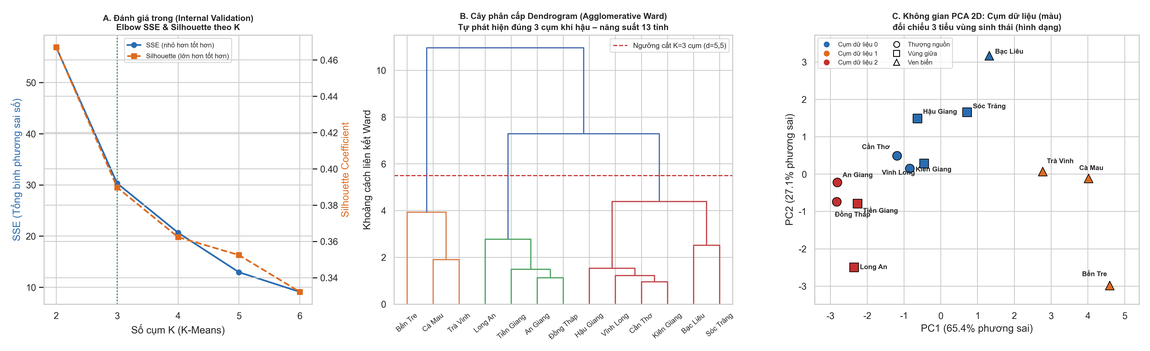

In [7]:
display(pd.read_csv('results/metrics/clustering_13provinces_validation.csv')[['algorithm','n_clusters_found','n_noise_points','internal_sse','internal_silhouette','internal_calinski_harabasz','external_ari_vs_subregion','external_nmi_vs_subregion']])
display(pd.read_csv('results/metrics/clustering_13provinces_assignments.csv')[['province','ecological_subregion','KMeans_K3','KMedoids_PAM_K3','Agglomerative_Ward_K3','DBSCAN_eps2_8_min2']])
display(Image('results/figures/09_clustering_13provinces_dendrogram_and_pca.png', width=1020))

## Bước 7. Khai phá Luật Kết hợp Định lượng — Apriori (Buổi 06–07)

antecedent,consequent,support,confidence,lift,leverage,conviction
MưaTiềnVụ=Cao AND Vùng=ThượngNguồn,NăngSuấtĐX=Cao,0.0945,1.0000,3.0238,0.0632,999.0000
ENSO=LaNiña AND Vùng=ThượngNguồn,NăngSuấtĐX=Cao,0.1024,0.8125,2.4568,0.0607,3.5696
Gió2m=Mạnh AND MưaTiềnVụ=TB,NăngSuấtĐX=Thấp,0.0945,0.7059,2.0848,0.0492,2.2488
MưaTiềnVụ=TB AND Vùng=VenBiển,NăngSuấtĐX=Thấp,0.0866,0.6875,2.0305,0.0440,2.1165
VPD=TB AND Vùng=ThượngNguồn,NăngSuấtĐX=Cao,0.0945,0.6667,2.0159,0.0476,2.0079
ENSO=LaNiña AND VPD=TB,NăngSuấtĐX=Cao,0.1024,0.6500,1.9655,0.0503,1.9123
Vùng=VenBiển,NăngSuấtĐX=Thấp,0.1811,0.6216,1.8360,0.0825,1.7480
ENSO=LaNiña AND Vùng=VùngGiữa,NăngSuấtĐX=TB,0.0945,0.6000,1.8143,0.0424,1.6732
Gió2m=Mạnh AND Vùng=VenBiển,NăngSuấtĐX=Thấp,0.1496,0.5938,1.7536,0.0643,1.6281
Gió2m=Yếu AND Vùng=ThượngNguồn,NăngSuấtĐX=Cao,0.1181,0.5769,1.7445,0.0504,1.5820


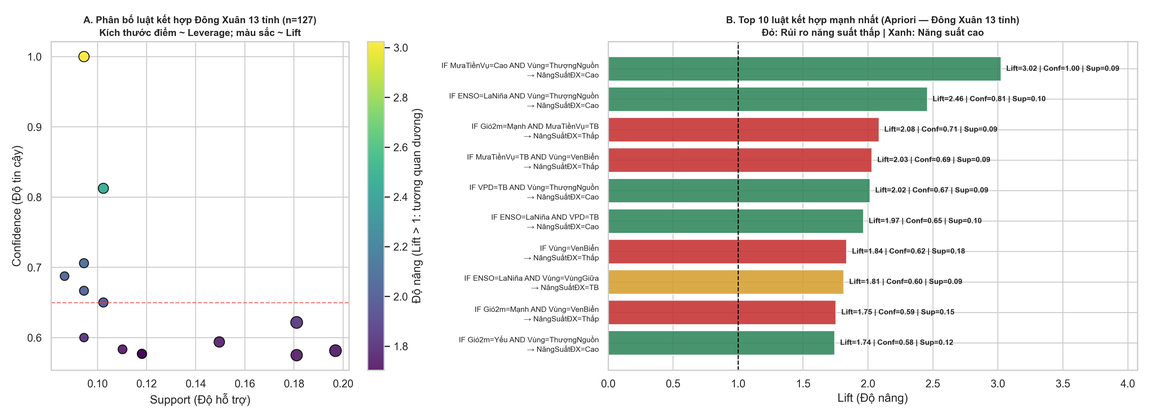

In [8]:
rules = pd.read_csv('results/metrics/association_rules_agroclimatic.csv')
display(rules[rules['dataset']=='TrackA_DX_13Prov_n127'].head(10)[['antecedent','consequent','support','confidence','lift','leverage','conviction']])
display(Image('results/figures/10_association_rules_lift_confidence.png', width=980))